In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split,StratifiedKFold,RandomizedSearchCV,GridSearchCV
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv("/content/movies_classification (1).csv")

In [ ]:
print("shape:",df.shape)
print(df.head())
print(df.info())
print("Missing values per column:\n",df.isnull().sum())
target_col="Start_Tech_Oscar"
print("Target distribution:\n",df[target_col].value_counts())

shape: (506, 19)
   Marketing expense  Production expense  Multiplex coverage     Budget  \
0            20.1264               59.62               0.462  36524.125   
1            20.5462               69.14               0.531  35668.655   
2            20.5458               69.14               0.531  39912.675   
3            20.6474               59.36               0.542  38873.890   
4            21.3810               59.36               0.542  39701.585   

   Movie_length  Lead_ Actor_Rating  Lead_Actress_rating  Director_rating  \
0         138.7               7.825                8.095            7.910   
1         152.4               7.505                7.650            7.440   
2         134.6               7.485                7.570            7.495   
3         119.3               6.895                7.035            6.920   
4         127.7               6.920                7.070            6.815   

   Producer_rating  Critic_rating  Trailer_views 3D_available  Time_t

In [ ]:
cat_cols=df.select_dtypes(include=['object','category']).columns.tolist()
cols_to_dummy=list(set(cat_cols+[c for c in ['3D_available','Genre']
                                 if c in df.columns]))
print("Converting to dummies:",cols_to_dummy)
df=pd.get_dummies(df,columns=cols_to_dummy,drop_first=True)



Converting to dummies: ['3D_available', 'Genre']


In [ ]:
x=df.drop(columns=[target_col])
y=df[target_col].astype(int)
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

baseline=xgb.XGBClassifier(use_label_encoder=False,eval_metric='logloss',random_state=42,n_jobs=-1)

In [ ]:
baseline.fit(x_train, y_train)
y_pred_baseline = baseline.predict(x_test)
print("Baseline Accuracy:",accuracy_score(y_test,y_pred_baseline))
print(classification_report(y_test,y_pred_baseline))
print("Confusion matrix:",confusion_matrix(y_test,y_pred_baseline))

Baseline Accuracy: 0.6176470588235294
              precision    recall  f1-score   support

           0       0.57      0.59      0.58        46
           1       0.65      0.64      0.65        56

    accuracy                           0.62       102
   macro avg       0.61      0.61      0.61       102
weighted avg       0.62      0.62      0.62       102

Confusion matrix: [[27 19]
 [20 36]]


In [ ]:
param_dist = {
    'n_estimators': [100, 300, 500, 800, 1200],#no of trees
    'max_depth': [3, 4, 5, 6, 7, 9],
    'learning_rate': [0.01, 0.03, 0.05, 0.08, 0.1],
    'gamma': [0, 0.05, 0.1, 0.2, 0.3],   #min loss reduction required to make a split
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],#Fraction of training rows used to build a tree
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],#Fraction of features columns used per tree
    'reg_alpha': [0, 0.001, 0.01, 0.1, 1],#L1 regularization on leaf weights
    'reg_lambda': [0.1, 1, 5, 10] #L2 regularization on leaf weights
}

In [ ]:
xgb_clf=xgb.XGBClassifier(use_label_encoder=False,eval_metric='logloss',random_state=42,n_jobs=-1)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
rs=RandomizedSearchCV(
    xgb_clf,
    param_distributions=param_dist,
    n_iter=60,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)
rs.fit(x_train,y_train)
print("Best param:",rs.best_params_)
print("Best CV f1:",rs.best_score_)

best=rs.best_estimator_
y_pred=best.predict(x_test)
print("Tuned Accuracy:",accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
print("Confusion matrix:",confusion_matrix(y_test,y_pred))

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best param: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.01, 'n_estimators': 1200, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0.05, 'colsample_bytree': 1.0}
Best CV f1: 0.6927049082368532
Tuned Accuracy: 0.5980392156862745
              precision    recall  f1-score   support

           0       0.56      0.54      0.55        46
           1       0.63      0.64      0.64        56

    accuracy                           0.60       102
   macro avg       0.59      0.59      0.59       102
weighted avg       0.60      0.60      0.60       102

Confusion matrix: [[25 21]
 [20 36]]


                feature  importance
15           Collection    0.073654
8       Producer_rating    0.061426
18          Genre_Drama    0.060695
3                Budget    0.058847
17         Genre_Comedy    0.056468
7       Director_rating    0.055731
9         Critic_rating    0.051327
11           Time_taken    0.051258
10        Trailer_views    0.049772
1    Production expense    0.048739
6   Lead_Actress_rating    0.048427
19       Genre_Thriller    0.047858
12      Twitter_hastags    0.046467
4          Movie_length    0.046007
0     Marketing expense    0.045915
16     3D_available_YES    0.044770
2    Multiplex coverage    0.041371
5    Lead_ Actor_Rating    0.037971
13       Avg_age_actors    0.037452
14        Num_multiplex    0.035845


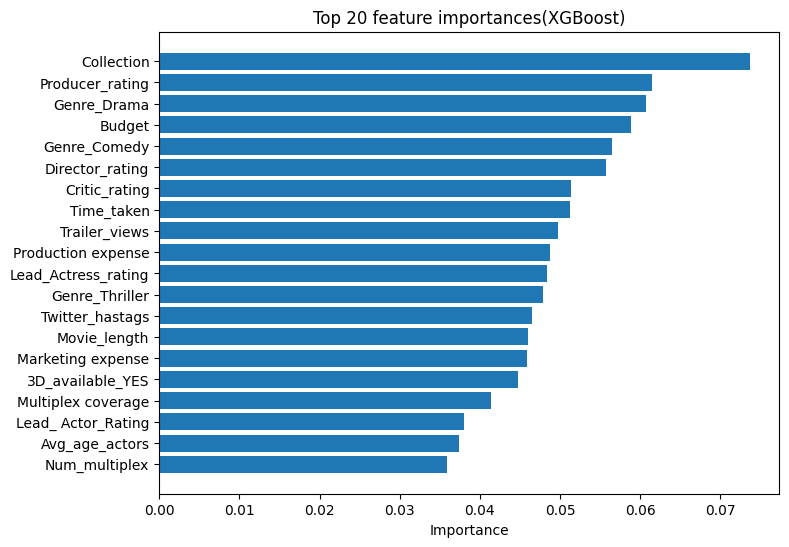

In [ ]:
fi=pd.DataFrame({'feature':x.columns,'importance':best.feature_importances_}).sort_values(by='importance',ascending=False)
print(fi.head(20))

plt.figure(figsize=(8,6))
plt.barh(fi['feature'].head(20)[::-1],fi['importance'].head(20)[::-1])
plt.xlabel('Importance')
plt.title('Top 20 feature importances(XGBoost)')
plt.tight_layout
plt.show()

In [ ]:
'''WHY ACCURACY IS STUCK AT 62%
1. All models are converging to the same accuracy
You already tried:
Logistic Regression
Random Forest
XGBoost (default)
XGBoost (tuned)
GridSearch
Randomized Search
CV scores
All these models giving 60–65% is the strongest possible evidence that:
The features simply do not contain enough information to predict the
target reliably.
Machine learning cannot create signal where none exists.
2. Your dataset is very small
Only 506 rows
After splitting: ~400 train rows
Many categorical variables → converted to many dummy variables
High dimensionality + small dataset = low generalization ability
Small datasets simply do not support high accuracy unless the problem is trivially
 separable.
3. Your target variable is extremely noisy
From the dataset:
Start_Tech_Oscar is influenced by:
Critics’ ratings
Technical innovation
Production quality, VFX quality
Real Oscar jury decisions'''

'WHY ACCURACY IS STUCK AT 62%\n1. All models are converging to the same accuracy\nYou already tried:\nLogistic Regression\nRandom Forest\nXGBoost (default)\nXGBoost (tuned)\nGridSearch\nRandomized Search\nCV scores\nAll these models giving 60–65% is the strongest possible evidence that:\nThe features simply do not contain enough information to predict the \ntarget reliably.\nMachine learning cannot create signal where none exists.\n2. Your dataset is very small\nOnly 506 rows\nAfter splitting: ~400 train rows\nMany categorical variables → converted to many dummy variables\nHigh dimensionality + small dataset = low generalization ability\nSmall datasets simply do not support high accuracy unless the problem is trivially\n separable.\n3. Your target variable is extremely noisy\nFrom the dataset:\nStart_Tech_Oscar is influenced by:\nCritics’ ratings\nTechnical innovation\nProduction quality, VFX quality\nReal Oscar jury decisions'

In [ ]:
#ensemble stacking
from sklearn.ensemble import StackingClassifier as SKStacking
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn import model_selection
from sklearn import datasets

iris=datasets.load_iris()
x,y=iris.data[:,1:3],iris.target

In [ ]:
estimators=[
    ('knn',KNeighborsClassifier(n_neighbors=1)),
    ('rf',RandomForestClassifier(random_state=1)),
    ('gnb',GaussianNB())
]


In [ ]:
stack=SKStacking(estimators=estimators,final_estimator=LogisticRegression(max_iter=500),
                cv=3)
scores=model_selection.cross_val_score(stack,x,y,cv=3,scoring='accuracy')
print("Stacking(sklearn)CV accuracy:",scores.mean())

Stacking(sklearn)CV accuracy: 0.9466666666666667


In [ ]:
#Voting
import numpy as np
from sklearn.ensemble import VotingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
import warnings
warnings.filterwarnings('ignore')
from sklearn import datasets
iris=datasets.load_iris()
x,y=iris.data[:,1:3],iris.target
clf1=LogisticRegression()
clf2=RandomForestClassifier(random_state=1)
clf3=GaussianNB()


In [ ]:
print("After five fold cross validation")
labels=['Logistic Regression','Random Forest','Naive Bayes Model']
for clf,label in zip([clf1,clf2,clf3],labels):
    scores=model_selection.cross_val_score(clf,x,y,cv=5,scoring='accuracy')
    print("Accuracy:",scores.mean(),"for ",label)

After five fold cross validation
Accuracy: 0.9533333333333334 for  Logistic Regression
Accuracy: 0.9400000000000001 for  Random Forest
Accuracy: 0.9133333333333334 for  Naive Bayes Model


In [ ]:
voting_clf_hard=VotingClassifier(estimators=[(labels[0],clf1),
                                             (labels[1],clf2),
                                             (labels[2],clf3)],
                                 voting='hard')
voting_clf_soft=VotingClassifier(estimators=[(labels[0],clf1),
                                             (labels[1],clf2),
                                             (labels[2],clf3)],
                                 voting='soft'
                                 )
labels_new=['Logistic Regression','Random Forest model','Naive Bayes model','Voting_Clf_hard','Voting_Clf_soft']

for clf,label in zip([clf1,clf2,clf3,voting_clf_hard,voting_clf_soft],labels_new):
    scores=model_selection.cross_val_score(clf,x,y,cv=5,scoring='accuracy')
    print("Accuracy:",scores.mean(),"for ",label)

Accuracy: 0.9533333333333334 for  Logistic Regression
Accuracy: 0.9400000000000001 for  Random Forest model
Accuracy: 0.9133333333333334 for  Naive Bayes model
Accuracy: 0.9533333333333334 for  Voting_Clf_hard
Accuracy: 0.9466666666666667 for  Voting_Clf_soft
